# 转化漏斗

回答：用户从「逛」到「买」流失在哪一环？不同品类、不同日期的转化效率有差别吗？

**口径说明**：漏斗按**用户去重**计算（不是行为条数），
即「9 天内至少浏览过的人」→「至少加购或收藏过的人」→「至少购买过的人」。
行为条数口径会把一个人点 10 次算成 10，转化率会被严重高估。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 1. 读取数据

数据已在「数据处理」阶段完成清洗（去越界、修正时区），这里只读 4 列，并用 dtype 压缩内存。

In [2]:
data = pd.read_csv(
    'data/UserBehavior_clean.csv',
    usecols=['user_id', 'category_id', 'behavior_type', 'timestamp'],
    dtype={'user_id': 'int32', 'category_id': 'int32',
           'behavior_type': 'category', 'timestamp': 'int64'},
    encoding='utf-8-sig',
)
print(data.shape)

# 三种漏斗阶段标记（加购和收藏合并为「意向」）
data['is_pv'] = (data['behavior_type'] == 'pv').astype('int8')
data['is_cf'] = data['behavior_type'].isin(['cart', 'fav']).astype('int8')
data['is_buy'] = (data['behavior_type'] == 'buy').astype('int8')

# 北京时间下的日期序号，用于按天看漏斗
data['day_idx'] = pd.to_datetime(data['timestamp'] + 8 * 3600, unit='s').dt.day_of_year.astype('int16')
data = data.drop(columns=['timestamp', 'behavior_type'])
data.head()

(100095231, 4)


,user_id,category_id,is_pv,is_cf,is_buy,day_idx
0,1,2520377,1,0,0,329
1,1,2520771,1,0,0,329
2,1,149192,1,0,0,329
3,1,4181361,1,0,0,329
4,1,2520377,1,0,0,329


## 2. 整体漏斗（9 天窗口，用户去重）

先按用户把三个阶段「压平」成 0/1 标记，再对人数求和。

In [3]:
flags = data.groupby('user_id')[['is_pv', 'is_cf', 'is_buy']].max()

n_pv = int(flags['is_pv'].sum())
n_cf = int(flags['is_cf'].sum())
n_buy = int(flags['is_buy'].sum())

funnel = pd.DataFrame({
    '人数': [n_pv, n_cf, n_buy],
    '占浏览用户(%)': [100.0,
                   round(n_cf / n_pv * 100, 2),
                   round(n_buy / n_pv * 100, 2)],
}, index=['浏览用户', '加购/收藏用户', '购买用户'])
funnel['环节转化率(%)'] = [None,
                        round(n_cf / n_pv * 100, 2),
                        round(n_buy / n_cf * 100, 2)]
funnel

,人数,占浏览用户(%),环节转化率(%)
浏览用户,984105,100.00,NaN
加购/收藏用户,859275,87.32,87.32
购买用户,672404,68.33,78.25


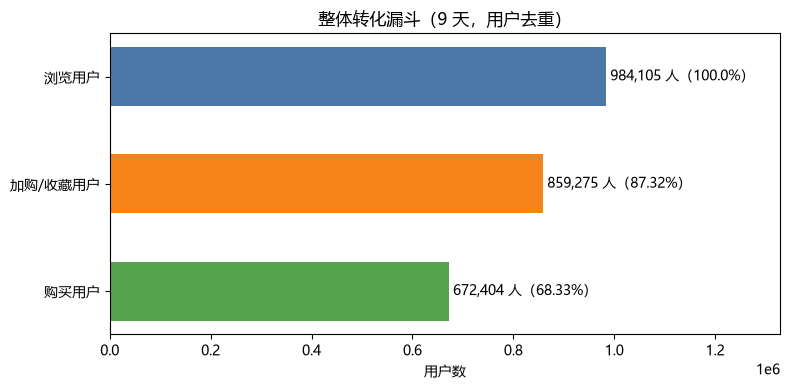

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#4C78A8', '#F58518', '#54A24B']
bars = ax.barh(funnel.index[::-1], funnel['人数'][::-1], color=colors[::-1], height=0.55)
ax.set_xlabel('用户数')
ax.set_title('整体转化漏斗（9 天，用户去重）')

for b, v, p in zip(bars, funnel['人数'][::-1], funnel['占浏览用户(%)'][::-1]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f' {v:,} 人（{p}%）',
            va='center', fontsize=10)

ax.set_xlim(0, funnel['人数'].max() * 1.35)
plt.tight_layout()
plt.show()

## 3. 每日漏斗

按「日期 × 用户」压平，再按天汇总，看转化率是否稳定。
注意这是**当日转化**，比 9 天窗口口径严格（用户当天逛完当天买才算）。

In [5]:
daily_flags = data.groupby(['day_idx', 'user_id'])[['is_pv', 'is_cf', 'is_buy']].max().reset_index()
daily = daily_flags.groupby('day_idx')[['is_pv', 'is_cf', 'is_buy']].sum()

daily.columns = ['浏览用户', '加购/收藏用户', '购买用户']
daily['加购率(%)'] = (daily['加购/收藏用户'] / daily['浏览用户'] * 100).round(2)
daily['购买率(%)'] = (daily['购买用户'] / daily['浏览用户'] * 100).round(2)

daily.index = [(pd.Timestamp('2017-01-01') + pd.Timedelta(days=int(d) - 1)).strftime('%m-%d')
               for d in daily.index]
daily

,浏览用户,加购/收藏用户,购买用户,加购率(%),购买率(%)
11-25,686953,316217,132622,46.03,19.31
11-26,695869,326897,136048,46.98,19.55
11-27,689260,315196,146934,45.73,21.32
11-28,688042,313807,139845,45.61,20.33
11-29,697542,321199,146220,46.05,20.96
11-30,709586,325823,146128,45.92,20.59
12-01,718184,341914,139971,47.61,19.49
12-02,939383,434686,174487,46.27,18.57
12-03,936431,429005,173225,45.81,18.50


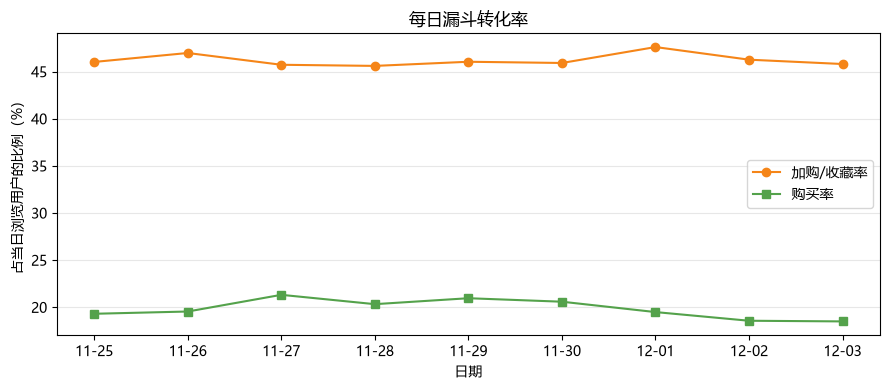

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily.index, daily['加购率(%)'], marker='o', color='#F58518', label='加购/收藏率')
ax.plot(daily.index, daily['购买率(%)'], marker='s', color='#54A24B', label='购买率')
ax.set_xlabel('日期')
ax.set_ylabel('占当日浏览用户的比例（%）')
ax.set_title('每日漏斗转化率')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. 品类漏斗（TOP10 品类）

这里用**行为条数**口径对比品类差异（品类 × 用户去重会产生上百万分组，成本太高）。
看的是「浏览多少次才换来一次加购/购买」，适合横向比较品类，不适合当整体转化率。

In [7]:
cat = data.groupby('category_id')[['is_pv', 'is_cf', 'is_buy']].sum()
cat = cat.nlargest(10, 'is_pv')
cat.columns = ['浏览量', '加购收藏量', '购买量']
cat['加购率(%)'] = (cat['加购收藏量'] / cat['浏览量'] * 100).round(2)
cat['购买率(%)'] = (cat['购买量'] / cat['浏览量'] * 100).round(2)
cat

,浏览量,加购收藏量,购买量,加购率(%),购买率(%)
category_id,,,,,
4756105,4477682,354519,28258,7.92,0.63
2355072,3151734,209108,12423,6.63,0.39
4145813,3150716,285085,31658,9.05,1.00
3607361,2976359,180436,12721,6.06,0.43
982926,2798730,243043,24825,8.68,0.89
2520377,2029469,153545,9812,7.57,0.48
4801426,1864651,190464,26495,10.21,1.42
1320293,1793240,148916,17137,8.30,0.96
2465336,1504738,139222,13350,9.25,0.89


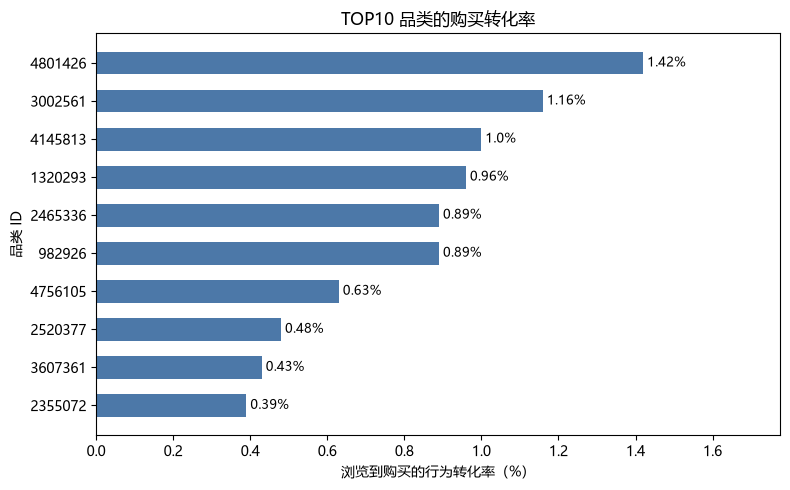

In [8]:
plot_df = cat.sort_values('购买率(%)')

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_df.index.astype(str), plot_df['购买率(%)'], color='#4C78A8', height=0.6)
ax.set_xlabel('浏览到购买的行为转化率（%）')
ax.set_ylabel('品类 ID')
ax.set_title('TOP10 品类的购买转化率')

for i, v in enumerate(plot_df['购买率(%)']):
    ax.text(v, i, f' {v}%', va='center', fontsize=9)

ax.set_xlim(0, plot_df['购买率(%)'].max() * 1.25)
plt.tight_layout()
plt.show()

## 结论

**1. 整体漏斗**：98.4 万浏览用户 → 85.9 万加购/收藏用户（87.3%）→ 67.2 万购买用户（占浏览 68.3%）。
意向到购买的环节转化率 78.3%，也就是说「一旦加购/收藏，八成会下单」。

**2. 重要前提：这个 68% 不能当真实淘宝水平。**
真实电商「访问→下单」通常在个位数百分比，这份数据是围绕购买行为筛选过的活跃用户集合，
所以绝对值只能内部比较，不能对外宣称「淘宝转化率 68%」。

**3. 每日漏斗很稳定**：加购率 45.6%~47.6%，购买率 18.5%~21.3%，没有明显波动。
12-02、12-03 流量大涨约 33%，但购买率反而略降（19.3% → 18.5%），
说明大促拉来的是「逛的人」更多，转化效率被稀释了一点。

**4. 品类差异明显**：TOP10 品类里，4801426 购买率最高（1.42%），4145813 次之（1.00%）；
而浏览量第一的 4756105 只有 0.63%，属于「流量大但成交弱」的典型。
最高与最低差约 3.6 倍，说明品类运营的重点应该是把低转化大流量品类的详情页/价格带做优化。